# 02 — Entraîner le GPT à écrire des comptines

On reprend le GPT caractère du script 06 de la séance 2, avec une seule
différence de fond : le texte d'entraînement n'est plus un long fleuve
(Shakespeare), mais une suite d'**exemples** indépendants, chacun de la forme

```
words: kettle, tea
Polly put the kettle on,
...
We'll all have tea.

```

Ce notebook :

1. relit le corpus du notebook 01 et construit le vocabulaire ;
2. définit un `Dataset` qui fabrique un exemple par comptine, avec des
   mots-clés **tirés à nouveau à chaque passage** ;
3. entraîne le GPT, en comptant en pas comme au script 06 ;
4. génère des comptines à partir de mots choisis (température, top-k du script 07) ;
5. mesure si le modèle **utilise vraiment** les mots qu'on lui donne ;
6. sauvegarde le modèle.

In [1]:
import random
import re
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from torch import nn
from torch.utils.data import DataLoader, Dataset, RandomSampler
from torch.utils.tensorboard import SummaryWriter

In [2]:
SEED = 1337
torch.manual_seed(SEED)
random.seed(SEED)

try:
    ROOT = Path(__file__).resolve().parent
except NameError:  # exécution dans une cellule Jupyter : `__file__` n'existe pas
    ROOT = Path.cwd()

DATA_DIR = ROOT / "data"
TRAIN_PATH = DATA_DIR / "comptines_train.txt"
VAL_PATH = DATA_DIR / "comptines_val.txt"
RUNS_DIR = ROOT / "runs" / "02_entrainement"
CHECKPOINT_DIR = ROOT / "checkpoints"

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"device : {device}")

device : cuda


## 1. Le corpus et le vocabulaire

`text.split("\n\n")` redonne la liste des comptines (notebook 01, chapitre 6).
Le vocabulaire est celui du script 01 : tous les caractères qui apparaissent.
On y ajoute ceux de la consigne `words: ...` pour être sûr qu'ils y sont.

In [3]:
train_rhymes = TRAIN_PATH.read_text(encoding="utf-8").split("\n\n")
val_rhymes = VAL_PATH.read_text(encoding="utf-8").split("\n\n")

chars = sorted(set("".join(train_rhymes + val_rhymes) + "words: ,\n"))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}


def encode(s: str) -> list[int]:
    """Texte → liste d'indices."""
    return [stoi[c] for c in s]


def decode(ids: list[int]) -> str:
    """Liste d'indices → texte."""
    return "".join(itos[i] for i in ids)


print(f"{len(train_rhymes):,} comptines d'entraînement   {len(val_rhymes):,} de validation   vocab_size : {vocab_size}")

2,682 comptines d'entraînement   299 de validation   vocab_size : 66


## 2. Un exemple par comptine

### Les mots-clés

Les deux fonctions du notebook 01 : les mots porteurs de sens d'une
comptine, et un tirage de 1 à 3 d'entre eux. On les recopie, comme le
script 07 recopie l'architecture du script 06.

In [4]:
def content_words(rhyme: str) -> list[str]:
    """Les mots porteurs de sens d'une comptine, sans doublon, dans l'ordre."""
    words = re.findall(r"[a-z]+", rhyme.lower())
    return list(dict.fromkeys(w for w in words if len(w) >= 3 and w not in ENGLISH_STOP_WORDS))


def pick_keywords(rhyme: str, rng: random.Random, max_keywords: int = 3) -> list[str]:
    """Tire de 1 à `max_keywords` mots-clés dans la comptine."""
    words = content_words(rhyme)
    return rng.sample(words, k=rng.randint(1, min(max_keywords, len(words)))) if words else []


def make_prompt(keywords: list[str]) -> str:
    """La consigne : la ligne des mots-clés."""
    return f"words: {', '.join(keywords)}\n"

### Le `Dataset`

Au script 06, un exemple était **n'importe quel** morceau de 64 caractères du
texte. Ici, un exemple est **une comptine entière, précédée de sa consigne**.
Le modèle doit voir la consigne et toute la comptine dans la même fenêtre :
`block_size = 256` couvre 94 % des comptines (notebook 01, chapitre 4) ; les
plus longues sont coupées.

Trois nouveautés par rapport au `CharDataset` du script 06 :

1. **Des mots-clés neufs à chaque passage.** `__getitem__` tire les mots au
   moment où on lui demande l'exemple. En 3 000 pas, chaque comptine passe
   une quinzaine de fois, avec une consigne différente presque à chaque fois.
   C'est de l'**augmentation de données** : le modèle ne peut pas apprendre
   « `kettle, tea` → *Polly* » par cœur, il doit apprendre que les mots de la
   consigne se retrouvent dans la comptine. Pour la validation, au contraire,
   on veut mesurer toujours la même chose : les mots-clés y sont tirés avec
   une graine fixe par comptine.

2. **Du remplissage (*padding*).** Les comptines n'ont pas toutes la même
   longueur, mais un lot est un tenseur rectangulaire `(batch_size,
   block_size)`. On complète la fin avec des retours à la ligne, et on met la
   cible à `-1` sur ces positions. `F.cross_entropy(..., ignore_index=-1)`
   ignore ces positions : le modèle n'est pas noté sur le remplissage. Grâce
   au masque causal de l'attention, le remplissage (toujours **après** le
   texte) ne change rien aux prédictions des positions qui comptent.

3. **On ne note pas la consigne.** Les mots-clés sont tirés au hasard : les
   prédire n'a pas de sens, et le modèle gaspillerait sa capacité à essayer.
   On met aussi les cibles à `-1` sur la ligne `words: ...`. Le modèle *lit*
   la consigne, mais n'apprend qu'à écrire la comptine qui suit. C'est le même
   procédé que pour entraîner les assistants comme ChatGPT : la loss ne porte
   que sur la réponse, pas sur la question.

In [5]:
block_size = 256


class RhymeDataset(Dataset):
    """Une comptine par exemple : consigne de mots-clés, comptine, ligne vide.

    Args:
        rhymes: Les comptines.
        block_size: Taille de la fenêtre ; les exemples plus longs sont coupés.
        fixed_keywords: Si vrai, les mots-clés de la comptine `i` sont
            toujours les mêmes (validation) ; sinon, ils changent à chaque appel.
    """

    def __init__(self, rhymes: list[str], block_size: int, fixed_keywords: bool = False) -> None:
        self.rhymes = rhymes
        self.block_size = block_size
        self.fixed_keywords = fixed_keywords

    def __len__(self) -> int:
        return len(self.rhymes)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, torch.Tensor]:
        rhyme = self.rhymes[i]
        rng = random.Random(i) if self.fixed_keywords else random
        prompt = make_prompt(pick_keywords(rhyme, rng))
        ids = torch.tensor(encode(prompt + rhyme + "\n\n")[: self.block_size + 1])
        n = len(ids) - 1

        x = torch.full((self.block_size,), stoi["\n"], dtype=torch.long)  # remplissage
        y = torch.full((self.block_size,), -1, dtype=torch.long)  # -1 : position ignorée par la loss
        x[:n], y[:n] = ids[:-1], ids[1:]  # y décalé d'un cran, comme au script 06
        y[: len(prompt) - 1] = -1  # on ne note pas la consigne
        return x, y


train_dataset = RhymeDataset(train_rhymes, block_size)
val_dataset = RhymeDataset(val_rhymes, block_size, fixed_keywords=True)

Regardons un exemple, en remplaçant les positions ignorées par `·` :

In [6]:
x0, y0 = train_dataset[0]
n = int((y0 != -1).nonzero().max()) + 1  # fin du texte, avant le remplissage
print("x :", repr(decode(x0[:n].tolist())))
print("y :", repr("".join("·" if t == -1 else itos[t] for t in y0[:n].tolist())))
print(f"\n{(y0 != -1).sum().item()} positions notées sur {block_size}")

x : "words: porridge, south, supping\nTHE man in the moon,\nCame tumbling down,\nAnd ask'd his way to Norwich,\nHe went by the south,\nAnd burnt his mouth\nWith supping cold pease-porridge.\n"
y : "·······························THE man in the moon,\nCame tumbling down,\nAnd ask'd his way to Norwich,\nHe went by the south,\nAnd burnt his mouth\nWith supping cold pease-porridge.\n\n"

148 positions notées sur 256


La cible de la dernière position de la consigne (le `\n` après les mots) est
la première lettre de la comptine : c'est là que l'écriture commence. Et le
dernier caractère à prédire est le second `\n`, la **fin de la comptine** :
le modèle apprend aussi quand s'arrêter.

### Les lots

Comme au script 06 : on compte en **pas**, et `RandomSampler` tire les
comptines au hasard avec remise. `batch_size = 16` au lieu de 32 : chaque
exemple fait 256 caractères au lieu de 64, un lot de 16 contient donc déjà
deux fois plus de caractères que ceux du script 06, et l'entraînement doit
tourner sur le CPU d'un portable.

In [7]:
batch_size = 16
n_embd = 128
n_head = 4
n_layer = 4
dropout = 0.2
learning_rate = 1e-3
eval_every = 250  # on mesure la validation tous les 250 pas
val_batches = 20  # 20 lots de 16 ≈ toute la validation


def make_train_loader(max_steps: int) -> DataLoader:
    """Un `DataLoader` qui tire `max_steps` lots au hasard dans le train."""
    sampler = RandomSampler(train_dataset, replacement=True, num_samples=max_steps * batch_size)
    return DataLoader(train_dataset, batch_size=batch_size, sampler=sampler)


val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    sampler=RandomSampler(val_dataset, replacement=True, num_samples=val_batches * batch_size),
)
xb, yb = next(iter(make_train_loader(max_steps=1)))
print(f"un lot : x {tuple(xb.shape)}   y {tuple(yb.shape)}")

un lot : x (16, 256)   y (16, 256)


## 3. Le modèle

L'architecture est **exactement** le GPT final du script 06, sous la forme
du script 07 (hyperparamètres passés explicitement). Un seul changement dans
`forward` : `ignore_index=-1` dans la loss.

`dropout = 0.2` au lieu de 0.1 : le corpus fait 400 000 caractères, moins de
la moitié de Shakespeare. Le modèle verra chaque comptine une quinzaine de
fois, et le risque qu'il les apprenne par cœur est plus grand.

In [8]:
class Head(nn.Module):
    """Une tête de self-attention masquée."""

    def __init__(self, n_embd: int, head_size: int, block_size: int, dropout: float) -> None:
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        _, T, _ = x.shape
        k, q = self.key(x), self.query(x)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        wei = self.dropout(F.softmax(wei, dim=-1))
        return wei @ self.value(x)


class MultiHeadAttention(nn.Module):
    """Plusieurs têtes en parallèle, concaténées puis projetées."""

    def __init__(self, n_embd: int, n_head: int, block_size: int, dropout: float) -> None:
        super().__init__()
        self.heads = nn.ModuleList(Head(n_embd, n_embd // n_head, block_size, dropout) for _ in range(n_head))
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.dropout(self.proj(torch.cat([h(x) for h in self.heads], dim=-1)))


class FeedForward(nn.Module):
    """MLP appliqué à chaque position indépendamment."""

    def __init__(self, n_embd: int, dropout: float) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd), nn.ReLU(), nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class Block(nn.Module):
    """Bloc Transformer pre-norm : attention puis feed-forward, avec résiduels."""

    def __init__(self, n_embd: int, n_head: int, block_size: int, dropout: float) -> None:
        super().__init__()
        self.sa = MultiHeadAttention(n_embd, n_head, block_size, dropout)
        self.ffwd = FeedForward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.sa(self.ln1(x))
        return x + self.ffwd(self.ln2(x))


class GPTLanguageModel(nn.Module):
    """GPT caractère du script 06 ; la loss ignore les cibles à -1."""

    def __init__(self, vocab_size: int, block_size: int, n_embd: int, n_head: int, n_layer: int,
                 dropout: float) -> None:
        super().__init__()
        self.block_size = block_size
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx: torch.Tensor, targets: torch.Tensor | None = None):
        B, T = idx.shape
        x = self.token_embedding_table(idx) + self.position_embedding_table(torch.arange(T, device=idx.device))
        logits = self.lm_head(self.ln_f(self.blocks(x)))
        if targets is None:
            return logits, None
        return logits, F.cross_entropy(logits.view(B * T, -1), targets.view(B * T), ignore_index=-1)


config = {"vocab_size": vocab_size, "block_size": block_size, "n_embd": n_embd,
          "n_head": n_head, "n_layer": n_layer, "dropout": dropout}
model = GPTLanguageModel(**config).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} paramètres")
print(f"loss avant entraînement : {model(xb.to(device), yb.to(device))[1].item():.4f}   (ln({vocab_size}) = {torch.log(torch.tensor(vocab_size)).item():.2f})")

841,538 paramètres


loss avant entraînement : 4.3133   (ln(66) = 4.19)


## 4. L'entraînement

La boucle du script 06, sans changement : `train_step` pour un pas, `test`
pour la validation, `run_training` qui les enchaîne et écrit les courbes dans
TensorBoard (`uv run tensorboard --logdir runs`). On garde aussi les mesures
dans une liste pour tracer la courbe ici.

In [9]:
def train_step(model: nn.Module, optimizer: torch.optim.Optimizer, X: torch.Tensor, Y: torch.Tensor) -> float:
    """Un pas d'entraînement sur un lot ; renvoie la loss du lot."""
    model.train()  # dropout actif
    _, loss = model(X.to(device), Y.to(device))  # 1. forward, loss comprise
    optimizer.zero_grad(set_to_none=True)
    loss.backward()  # 2. backward
    optimizer.step()  # 3. step
    return loss.item()


@torch.no_grad()
def test(model: nn.Module, loader: DataLoader) -> float:
    """Mesure la loss moyenne sur les lots du loader, sans apprendre."""
    model.eval()  # dropout coupé
    total = 0.0
    for X, Y in loader:
        _, loss = model(X.to(device), Y.to(device))
        total += loss.item()
    return total / len(loader)


def run_training(model: nn.Module, run: str, max_steps: int) -> list[tuple[int, float, float]]:
    """Entraîne pendant `max_steps` pas, mesure tous les `eval_every` pas.

    Returns:
        Les mesures `(pas, loss train, loss val)`.
    """
    torch.manual_seed(SEED)
    log_dir = RUNS_DIR / run
    shutil.rmtree(log_dir, ignore_errors=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    train_losses, history = [], []
    start = time.perf_counter()

    with SummaryWriter(log_dir=str(log_dir)) as writer:
        for step, (X, Y) in enumerate(make_train_loader(max_steps), start=1):
            train_losses.append(train_step(model, optimizer, X, Y))

            if step % eval_every == 0:
                train_loss = sum(train_losses) / len(train_losses)
                val_loss = test(model, val_loader)
                writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, step)
                history.append((step, train_loss, val_loss))
                print(f"pas {step:>5}   train {train_loss:.4f}   val {val_loss:.4f}   {time.perf_counter() - start:.0f} s")
                train_losses = []
    return history

3 000 pas : environ 1 heure sur le CPU d'un portable (≈ 1 s par pas),
quelques minutes sur un GPU.

In [10]:
max_steps = 3_000
history = run_training(model, "gpt_comptines", max_steps)

pas   250   train 2.5482   val 2.3872   15 s


pas   500   train 2.3639   val 2.2620   32 s


pas   750   train 2.2317   val 2.1031   44 s


pas  1000   train 2.0854   val 1.9526   61 s


pas  1250   train 1.9691   val 1.8537   74 s


...

pas  2000   train 1.7576   val 1.6422   130 s


pas  2250   train 1.6968   val 1.6075   148 s


pas  2500   train 1.6648   val 1.5824   170 s


pas  2750   train 1.6306   val 1.5106   192 s


pas  3000   train 1.5938   val 1.4943   220 s


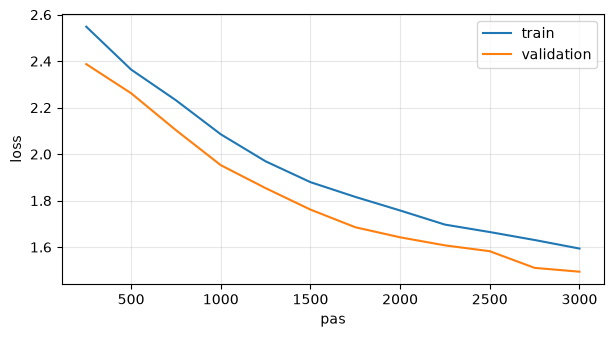

In [11]:
steps, train_curve, val_curve = zip(*history)
plt.figure(figsize=(7, 3.5))
plt.plot(steps, train_curve, label="train")
plt.plot(steps, val_curve, label="validation")
plt.xlabel("pas")
plt.ylabel("loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. Écrire une comptine

La fonction `generate` du script 07 (température et top-k), avec deux
ajouts pour notre usage :

- elle part de la consigne `words: ...\n` construite à partir des mots
  donnés ;
- elle **s'arrête** dès que le modèle écrit une ligne vide : la comptine est
  finie (c'est ce qu'il a appris avec le `\n\n` final de chaque exemple).

Les mots donnés doivent s'écrire avec les caractères du vocabulaire : on les
met en minuscules et on retire le reste (accents, chiffres).

In [12]:
@torch.no_grad()
def write_rhyme(words: list[str], temperature: float = 0.8, top_k: int | None = 10,
                max_new_tokens: int = 400) -> str:
    """Écrit une comptine à partir de mots-clés.

    Args:
        words: Les mots-clés.
        temperature: Divise les logits ; < 1 concentre, > 1 aplatit.
        top_k: Si fourni, ne tire que parmi les `top_k` caractères les plus probables.
        max_new_tokens: Garde-fou si le modèle n'écrit jamais de ligne vide.

    Returns:
        La comptine, sans la consigne.
    """
    model.eval()
    words = [re.sub(r"[^a-z]", "", w.lower()) for w in words]
    prompt = make_prompt([w for w in words if w])
    idx = torch.tensor([encode(prompt)], device=device)
    for _ in range(max_new_tokens):
        logits = model(idx[:, -model.block_size :])[0][:, -1, :] / temperature
        if top_k is not None:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = float("-inf")
        idx = torch.cat((idx, torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)), dim=1)
        if decode(idx[0, -2:].tolist()) == "\n\n":  # ligne vide : la comptine est finie
            break
    return decode(idx[0, len(prompt) :].tolist()).strip()


torch.manual_seed(SEED)
for words in [["cat", "moon"], ["king", "pie"], ["rain", "garden"], ["dog", "bone", "star"]]:
    print(f"--- {', '.join(words)} ---")
    print(write_rhyme(words), end="\n\n")

--- cat, moon ---


They a baby can,
Went to the with the baby the barn,
And the back of came better,
And sat old sparrook, "Oh, two make two that
And so she hay baby of the wown,
And would with more."

--- king, pie ---


As I so with had man of hill,
The him home is more be his bowl,
And poked it my pier made of white in his pie.

--- rain, garden ---


As Robin a man a come,
A-pade a sail,
A gave and the comen the sat to tall.

--- dog, bone, star ---


We'll to the brog to stick,
The beller's boy boy he,
Will was boy day clook.



## 6. Le modèle utilise-t-il les mots ?

Lire quelques comptines ne suffit pas pour conclure. Mesurons-le sur la
validation, des comptines que le modèle n'a jamais vues :

- pour chaque comptine de validation, on prend ses mots-clés (les mêmes que
  ceux de la loss de validation) et on fait écrire le modèle ;
- **taux de reprise** : la part des mots-clés qui apparaissent dans ce qu'il
  a écrit ;
- **référence** : la même mesure, mais en comparant aux mots-clés d'une
  *autre* comptine. C'est le taux qu'on obtiendrait si le modèle ignorait la
  consigne et que les mots apparaissaient par hasard.

Si la consigne sert à quelque chose, le premier taux doit être nettement
au-dessus du second.

In [13]:
def keyword_hits(keywords: list[str], text: str) -> float:
    """Part des mots-clés présents (comme mots entiers) dans le texte."""
    words = set(re.findall(r"[a-z]+", text.lower()))
    return sum(k in words for k in keywords) / len(keywords)


torch.manual_seed(SEED)
n_eval = 60
keyword_sets = [pick_keywords(r, random.Random(i)) for i, r in enumerate(val_rhymes[:n_eval])]
keyword_sets = [k for k in keyword_sets if k]
generated = [write_rhyme(k) for k in keyword_sets]

hits = sum(keyword_hits(k, g) for k, g in zip(keyword_sets, generated)) / len(generated)
shifted = generated[1:] + generated[:1]  # la comptine écrite pour une AUTRE consigne
baseline = sum(keyword_hits(k, g) for k, g in zip(keyword_sets, shifted)) / len(generated)
print(f"taux de reprise des mots-clés : {hits:.1%}")
print(f"référence (consigne ignorée)  : {baseline:.1%}")

taux de reprise des mots-clés : 17.2%
référence (consigne ignorée)  : 1.9%


## 7. Sauvegarder

Comme au script 06 : les poids, la configuration (pour reconstruire
l'architecture) et le vocabulaire (sans lui, les indices ne veulent rien
dire). Le notebook suivant recharge ce fichier pour générer sans
réentraîner.

In [14]:
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint = {
    "model_state": model.state_dict(),
    "config": config,
    "chars": chars,
    "val_loss": history[-1][2],
    "keyword_hits": hits,
}
torch.save(checkpoint, CHECKPOINT_DIR / "gpt_comptines.pt")
print(f"→ {(CHECKPOINT_DIR / 'gpt_comptines.pt').relative_to(ROOT)}")

→ checkpoints\gpt_comptines.pt
